# Roots of nonlinear equations

In this section, we will discuss several methods for solving nonlinear equations (e.g., $f(x) = 0$) and systems of nonlinear equations for which the methods used for linear equations are not applicable. 

Take, for example, the following equation for $x$

$$ 
x + \exp (-x) = 2 ~~.
$$

This is an equation that cannot be solved analytically as it is a [transcendental equation](https://en.wikipedia.org/wiki/Transcendental_equation). To get an idea of whether this equation has a solution, or how many solutions, we split the equation into two equations, i.e., two curves

\begin{align}
y_1(x) &= x + \exp(-x) \\ 
y_2(x) &= 2
\end{align}

and determine the point(s) of intersection. By **visual inspection** (see below), we see that there is one solution with a value between $1.75$ and $2$ (see gray band). 

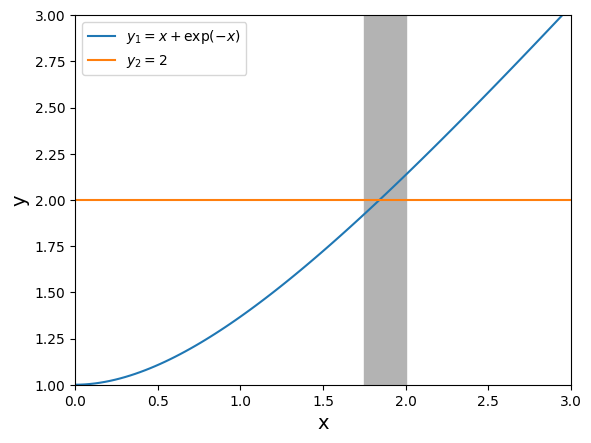

In [28]:
import numpy as np
import matplotlib.pyplot as plt

def y1(x):
    return x + np.exp(-x)

def y2(x):
    return 2* np.ones_like(x)

x = np.linspace(0, 3, 100)
y = y1(x)

plt.plot(x, y1(x), label="$y_1 = x+\exp(-x)$")
plt.plot(x, y2(x), label="$y_2 = 2$")
plt.xlim(0,3)
plt.ylim(1,3)
plt.xlabel("x",fontsize = 14)
plt.ylabel("y",fontsize = 14)
plt.axvspan(1.75, 2.0, color="0.7", zorder=0)
plt.legend()
plt.show()

Note that **the splitting is not unique** as we could have chosen:

\begin{align}
y_1(x) &= x  \\ 
y_2(x) &= 2 - \exp(-x)
\end{align}

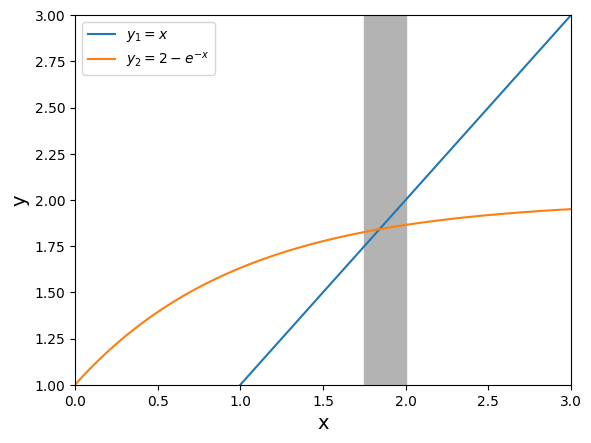

In [29]:
import numpy as np
import matplotlib.pyplot as plt

def y1(x):
    return x 

def y2(x):
    return 2 - np.exp(-x)

x = np.linspace(0,3,100)

plt.plot(x, y1(x), label="$y_1 = x$")
plt.plot(x, y2(x), label="$y_2 = 2 - e^{-x}$")
plt.xlabel("x", fontsize = 14)
plt.ylabel("y", fontsize = 14)
plt.xlim(0,3)
plt.ylim(1,3)
plt.axvspan(1.75, 2.0, color="0.7", zorder=0)
plt.legend()
plt.show()

**Of course, the solution (i.e., the $x$-coordinate of the intersection) is the same as above.**

This visual approach to finding roots is (at best) only of limited use in higher dimensions.

## Relaxation method

The **relaxation method** is an iterative method to find the solutions of nonlinear equations $f(x) = 0$. We reformulate root finding as a fixed-point problem:

$$
x - f(x) \equiv g(x) = x
$$

Let's consider (again) the function
$$ 
x + \exp (-x) = 2 \longrightarrow \boxed{x = 2-  \exp (-x) \equiv g(x)}
$$

To find the fixed point, we write the boxed equation as an iterative map:

$$
x_{n+1} = 2 - \exp(-x_n) \equiv g(x_n) \quad (\mathrm{with\ some\ initial\ } x_0)
$$

There are many options how to write this map. The success of the procedure will depend on that choice.


In [30]:
import numpy as np
from matplotlib import pyplot as plt

def g(x):
    return 2. - np.exp(-x)

def iterative_map(g, x0=0.5, Nmax=100, eps=1e-8):
    xn = [x0]
    xold = xn[0]
    for i in range (Nmax):
        xnew = g(xold)
        xn.append(xnew)
        if np.allclose(xnew, xold, atol=eps, rtol=0):
            break
        else:
            xold = xnew    
    return np.array(xn)

xn_iter = iterative_map(g=g, x0=0.5, Nmax=500)

import pandas as pd
pd.DataFrame(data={"xn": xn_iter})

,xn
0,0.500000
1,1.393469
2,1.751787
3,1.826536
4,1.839030
5,1.841028
6,1.841346
7,1.841396
8,1.841404
9,1.841405


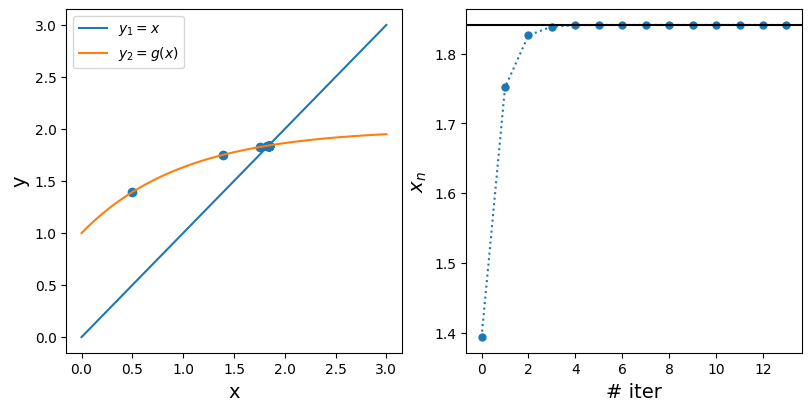

In [31]:
def make_plot(g, x0=0.5, x_range=(0,3), Nmax=100, eps=1e-9, method=iterative_map):

    x = np.linspace(*x_range,100)
    y2 = g(x)

    xn_iter = method(g=g, x0=x0, Nmax=Nmax, eps=eps)
    xn_iter_index = list(range(len(xn_iter)))

    fig, axs = plt.subplots(1, 2, figsize=(8,4), constrained_layout=True)
    # left panel
    axs[0].plot(x, x, label="$y_1 = x$")
    axs[0].plot(x, y2, label="$y_2 = g(x)$")
    axs[0].scatter(xn_iter, g(xn_iter), marker="o")
    axs[0].set_xlabel("x", fontsize = 14)
    axs[0].set_ylabel("y", fontsize = 14)
    axs[0].legend()

    # right panel
    axs[1].plot(xn_iter_index, g(xn_iter), ls=":", marker="o", ms=5)
    axs[1].set_ylabel("$x_n$", fontsize = 14)
    axs[1].set_xlabel("# iter", fontsize = 14)
    axs[1].axhline(xn_iter[-1], c="k")

    return fig, axs, pd.DataFrame(data={"xn": xn_iter})

fig, axs, df = make_plot(g=g, x0=0.5, x_range=(0,3), Nmax=100, eps=1e-9)


### Another example

But it turns out that this simple method **does not always work**. Take, for example:

$$ 
x - \exp (1-x^2) = 0 
$$

This nonlinear equation has the solution of $x=1$, which can be seen by inserting $x=1$ or by looking for the intersection of 

\begin{align}
y_1(x) &= x\\
y_2(x) &\equiv g(x) = \exp (1-x^2)
\end{align}

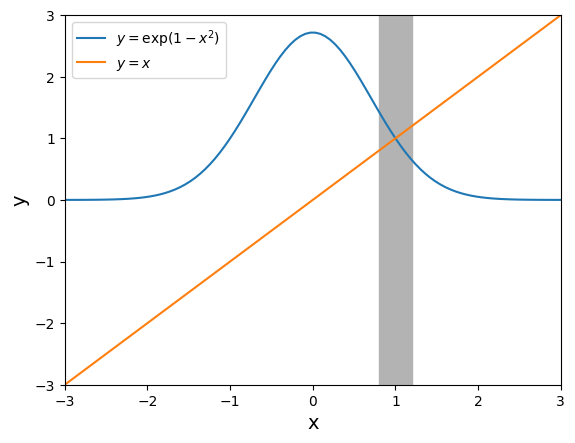

In [32]:
import numpy as np
import matplotlib.pyplot as plt

def g(x):
    return np.exp(1-x**2)

x = np.linspace(-3,3,100)

plt.xlim(-3,3)
plt.ylim(-3,3)
plt.xlabel("x",fontsize = 14)
plt.ylabel("y",fontsize = 14)
plt.plot(x, g(x), label="$y=\exp(1-x^2)$")
plt.plot(x, x, label="$y=x$")
plt.axvspan(0.8, 1.2, color="0.7", zorder=0)
plt.legend()
plt.show()

We write the nonlinear equation as a map, i.e.

$$x_{n+1} = \exp ( 1-x_n^2 )\equiv f(x_n)$$


and execute the same iterative scheme as above. This time it doesn't work, the sequences of values $x_1,x_2,x_3,\ldots$ does not converges to a fixed point, it oscillates instead.

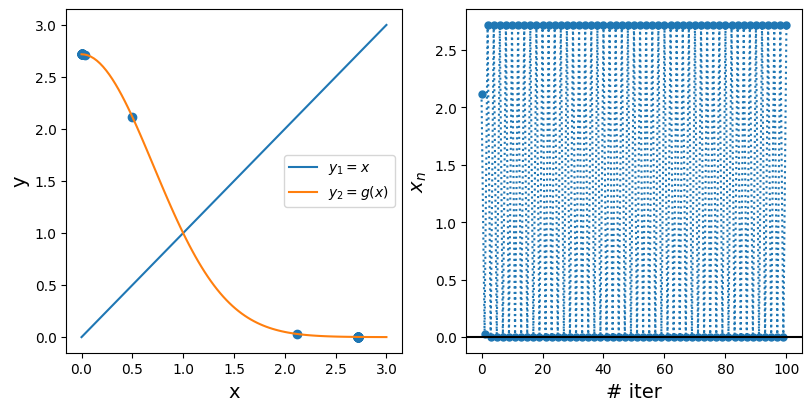

In [33]:
fig, ax, df = make_plot(g=g, x0=0.5, x_range=(0,3), Nmax=100, eps=1e-9)

As we can see, the algorithm does not converge. We can try different initial $x_0$, but **(unless $x_0=1$) we find no convergence pattern**. Why? Let's investigate the convergence.

### Condition for convergence
The above examples raise the question of whether we can find criteria when the iteration converges towards the equation's solution(s) and how we can modify the scheme so that a diverging iteration becomes a converging iteration.

**If the process works, an initial point $x$ is *attracted* to the solution $x$ as the iteration proceeds**, which becomes the *fixed point* $x^\star$. Let us consider the iterative map 

$$
x_{n+1} = f(x_n)
$$

with a fixed point (i.e. solution) $x = x^\star$, where $f(x^\star) = x^\star$. Let us pick a starting point near the fixed point, i.e.

$$
x_n = x^\star + y_n
$$

where $y_n$ is a sufficiently small (see below) deviation from the solution. Inserting this into the map yields

$$
x^\star + y_{n+1} = f(x^\star + y_n) = \underbrace{f(x^\star}_{=x^\star}) + f^\prime(x^\star) y_n + O(y_n^2)
$$

Sufficiently small means $|y_n f^\prime(x^\star)| \ll |f(x^\star)|$. Then

$$
\boxed{
y_{n+1} = f^\prime(x^\star )y_n}
$$

This equation implies that the sequence of deviations declines in the process if $|f^\prime(x^\star )|<1$, but not for $|f^\prime(x^\star )|>1$. In the latter case, the procedure will not converge to the fixed point, i.e., the solution.

#### Example
$$
x = 2 - \exp(-x) = f(x)
$$


With the solution $x^* \approx 1.84$

$$
|f^\prime (x^*)| = \exp(-x^*) \approx 0.16 < 1
$$

We conclude that the iteration $x_{n+1} = f(x_n)$ converges to the root of the equation. 

#### Example
$$
x = \exp(1-x^2) = f(x)
$$


With the solution $x^* = 1$

$$
|f^\prime (x^*)| = |-2x^*\exp(1-{x^*}^2)| = 2 > 1
$$

We conclude that the iteration $x_{n+1} = f(x_n)$ **does not** converge to the root of the equation. 

### Remedy if $|f^\prime(x^*)| > 1$
In this case, the inverse map will work if $f(x)$ can be inverted. We **invert** the equation

$$
x^* = f(x^*)
$$

to

$$
g(x^*) \equiv f^{-1}(x^*) = x^*
$$

and the subsequent iterated map to find $x^*$

$$
\boxed{
x_{n+1} = g(x_n)}
$$

This map will converge to the solution $x^*$, if

$$
|g^\prime(x^*)| = \left|{d \over dx}f^{-1}(x^*)\right| < 1
$$

Let's compute this derivative. Taking the derivative of

$$
f(f^{-1}(x)) = x
$$

and using the chain rule, we find

$$
f^\prime(f^{-1}(x))\cdot {d \over dx}f^{-1}(x) = 1
$$

and finally

$$ 
\boxed{
g^\prime(x) = {d \over dx}f^{-1}(x) = {1 \over f^\prime (f^{-1}(x))} \longrightarrow g^\prime(x^*) = {1 \over f^\prime (x^*)}}
$$

The result is known as the [**inverse function rule**](https://en.wikipedia.org/wiki/Inverse_function_rule). Hence, if $|f^\prime(x^*)| > 1$ then $|g^\prime(x^*)|<1$ and the iteration will converge to the solution $x^*$

#### Example
$$
x = \exp(1-x^2) \equiv f(x)
$$

Here, as noted before $|f^\prime(x^*)| = |f^\prime(1)| = 2$. Inverting this equation, 

$$
\ln(x) = 1 - x^2 \Rightarrow x = \sqrt{1 - \ln(x)} \equiv g(x)
$$

Then

$$
g^\prime(x) = -{1 \over 2x\sqrt{1 - \ln(x)}}
$$

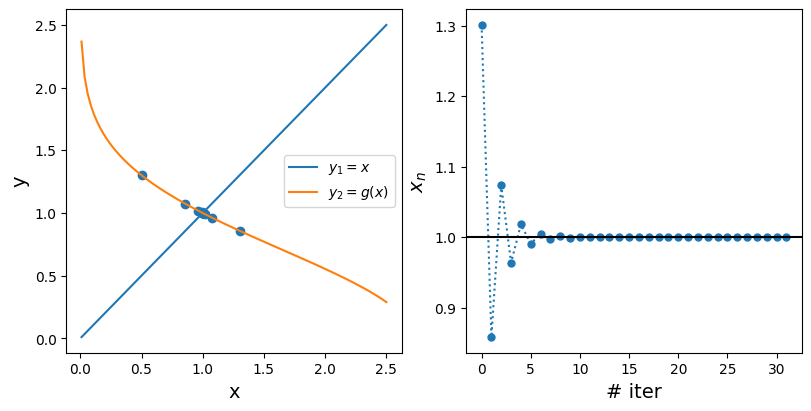

In [34]:
def g(x):
    return np.sqrt(1-np.log(x))

fig, ax, df = make_plot(g=g, x0=0.5, x_range=(0.01, 2.5), Nmax=100, eps=1e-9)

### Error analysis

We know from the analysis above when the method works. Now, we discuss how to estimate the deviation of the estimated solution from the true solution after a number of iterations. For the deviations $y_n$ and $y_{n+1}$ after steps $n$ and $n+1$ we have

\begin{align}
x_n &= x^* + y_n \\
x_{n+1} &= x^* + y_{n+1}
\end{align}

and from the linear analysis above

$$
\boxed{
y_{n+1} = f^\prime (x^*)y_n}
$$

The latter equation tells us that the **convergence is linear**, i.e., the deviation at step $n+1$ is proportional to the deviation at step $n$.

By combining the first two equations, we can estimate the error, i.e.,

\begin{align}
y_{n+1} - y_n &= y_n ( f^\prime (x^*) -1 ) \\ 
&\equiv x_{n+1} - x_n
\end{align}

and hence

$$
y_n = {x_{n+1} - x_n \over f^\prime (x^*) -1}
$$

Since we do not know the solution, we approximate $x^*$ with the iteration $x_n$ and hence

$$
\boxed{
y_n \approx {x_{n+1} - x_n \over f^\prime (x_n) -1}}
$$

and for the deviation $y_{n+1}$,

$$
\boxed{
y_{n+1} = f^\prime (x^*)y_n \approx {x_{n+1} - x_n \over 1 - {1 \over f^\prime (x_n)}}}
$$


#### Example

Let us test this error estimate using the mapping $x_{n+1}= f(x_n) = \sqrt{1 - \ln(x_n)}$, for which we know the solution $x^*=1$ and hence know the actual error after each iteration, allowing us to benchmark our error estimate. Also, we do not need to know the actual solution to estimate the error of the estimate. 

With

$$
f^\prime(x_n) = -{1 \over 2x_n\sqrt{1 - \ln(x_n)}}
$$

we have

$$
y_{n+1} = {x_{n+1} - x_n \over 1+2x_n\sqrt{1 - \ln(x_n)}}
$$

In [30]:
# iterative solution of x = sqrt(1-log(x))
import numpy as np

x1 = 2.5
xstar = 1
est_err = []
for i in range(1,20,1):
    x2 = np.sqrt(1. - np.log(x1))
    actual_error = np.abs(xstar - x2)
    estimated_error = abs((x2 - x1)/(1 + 2*x1*np.sqrt(1.-np.log(x1))))
    est_err.append(estimated_error)
    print(f"x = {x2:1.5e}, actual deviation = {actual_error:1.5e}, estimated deviation = {estimated_error:1.5e}")
    x1 = x2

x = 2.89326e-01, actual deviation = 7.10674e-01, estimated deviation = 9.03560e-01
x = 1.49673e+00, actual deviation = 4.96731e-01, estimated deviation = 6.47026e-01
x = 7.72474e-01, actual deviation = 2.27526e-01, estimated deviation = 2.18652e-01
x = 1.12168e+00, actual deviation = 1.21676e-01, estimated deviation = 1.27775e-01
x = 9.40838e-01, actual deviation = 5.91619e-02, estimated deviation = 5.81354e-02
x = 1.03004e+00, actual deviation = 3.00409e-02, estimated deviation = 3.03596e-02
x = 9.85090e-01, actual deviation = 1.49104e-02, estimated deviation = 1.48385e-02
x = 1.00748e+00, actual deviation = 7.48334e-03, estimated deviation = 7.50229e-03
x = 9.96265e-01, actual deviation = 3.73471e-03, estimated deviation = 3.73010e-03
x = 1.00187e+00, actual deviation = 1.86911e-03, estimated deviation = 1.87028e-03
x = 9.99066e-01, actual deviation = 9.34117e-04, estimated deviation = 9.33827e-04
x = 1.00047e+00, actual deviation = 4.67168e-04, estimated deviation = 4.67241e-04
x = 

Text(0, 0.5, 'est. error')

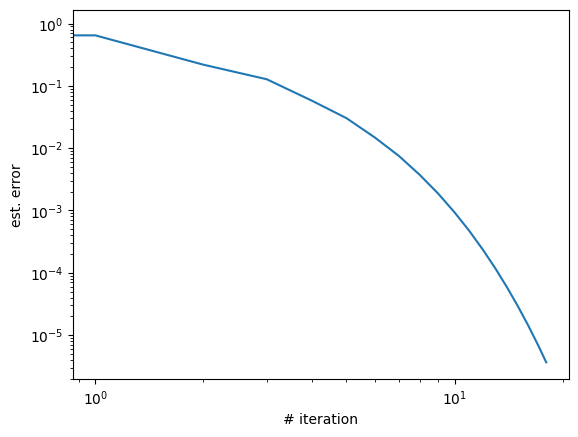

In [36]:
import matplotlib.pyplot as plt
plt.loglog(est_err)
plt.xlabel("# iteration")
plt.ylabel("est. error")

 ### Summary of the relaxation method
 
* The relaxation method is very useful for solving nonlinear equations. **But it does not always work.**
* If $|f’(x^*)| > 1$, we can try to invert the function to get $f^{-1}(x)$, since $|f'(x^*)| > 1$ the derivative of $f^{-1}(x^*)$ should be less than one and the iteration will converge.
* It is not always possible to invert a function, but cases where one can invert the function should work with the relaxation method.

## Bisection method

The bisection or **binary search** method is relatively slow but has the advantage that it will always succeed. We are looking for a root of the (continuous) function $f(x)$. The method is based on the [**intermediate value theorem**](https://en.wikipedia.org/wiki/Intermediate_value_theorem).

1. Find **initial values** $x_1$ and $x_2$ where $f(x_1) < 0$ and $f(x_2)>0$. (Also known as root bracketing.)

<img src="notes/bisection/bisec-001.jpg"> 

2. Pick the **point half** in between $x_1$ and $x_2$, i.e. 

$$
x_3 = {1 \over 2}(x_1 + x_2)
$$

3. If $f(x_3) > 0$, the root must be in the interval between and $x_1$ and $x_3$ which is **half the size** as the original interval between $x_1$ and $x_2$. Then repeat step 2 with $x_3 \rightarrow x_2$ 

<img src="notes/bisection/bisec-002.jpg">

4. If $f(x_3) < 0$, the root must be in the interval between $x_3$ and $x_2$ which is **half the size** as the original interval between $x_1$ and $x_2$.** Then repeat step 2 with $x_3 \rightarrow x_1$   

<img src="notes/bisection/bisec-003.jpg">

5. **Repeat** the steps above until the size of the current interval in which the root must be is smaller than the required accuracy of the root

### Error and convergences

Initially, the root is somewhere between $x_1$ and $x_2$ ([intermediate value theorem](https://en.wikipedia.org/wiki/Intermediate_value_theorem)), and hence the error estimate is $y_0 = |x_1 - x_2|$. In each iteration step, the interval is reduced by a factor of two, and so is the error estimate. Hence:

$$
y_{n+1} = y_n 2^{-1}
$$

Therefore, the **convergence** is just as for the relaxation method **linear**. After $n$ iterations, the error is

$$
y_n = y_0 2^{-n}
$$

which allows us to calculate how often we have to iterate until we obtain the root at a 
given error of $\epsilon$, i.e.

$$\boxed{
n_{max} = \log_2 \left ( {y_0 \over \epsilon }\right) 
}
$$

For example, if require a precision of $\epsilon = 10^{-10}$ with an initial interval of length $y_0 = 1$, we need $n_{max} = 34$. 

In [2]:
import numpy as np
def nmax(y0, eps=1e-10):
    return int(np.ceil(np.log2(y0/eps)))
nmax(1)

34

`log2()` is a slowly growing function, even if $y_0$ is much larger than $\epsilon$ this is not a lot of steps. If we start with a $y_0=10^{10}$ and we require an accuracy of $\epsilon=10^{-10}$, that still "only" requires $\log_2(10^{20}) \approx 67$ steps:

In [3]:
nmax(y0=1e10, eps=1e-10)

67

### Library Functions

There are library functions for a bisection search, e.g., see [`scipy.optimize.bisect()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.bisect.html).


### Summary

* **Bisection does have a number of shortcomings**. Obviously, if $f(x_1)$ and $f(x_2)$ have the **same sign**, you can not find a root. This may be because there is no root between these values, or because there are an even number, or because the function just touches zero but doesn’t cross it.
* Thus, bisection works best if you know enough about your function to know some places where it is positive and negative.
* If you are looking for a root near a particular value of $x$, start with $x_1$ and $x_2$ near that value. If they don’t bracket the root, keep doubling the distance to $x_1$ and $x_2$ until they bracket the root.
* **Bisection only works for single equations of one variable.**

In [6]:
def f(x):
    return (x**2 - 1)
from scipy import optimize
optimize.bisect(f, 0, 2)  # test also 2 --> -2. Question: what do you expect?

1.0

## Newton's Method

Newton's method is a **fast iterative method** with a quadratic convergence. The starting point is a point $x_1$ that is not too far from the desired root. We construct the **tangent line** at $x_1$, i.e.

$$ \boxed{
y(x) = f(x_1) + f^\prime(x_1)(x - x_1)}
$$

<img src="notes/Newton/Newton-001.jpg">

and determine the **intersection of this line with the $x$-axis**, our first estimate of the root, i.e.,

$$
x_2 = x_1 - {f(x_1) \over f^\prime(x_1)} \quad \mathrm{assuming} \quad  f^\prime(x_1) \neq 0
$$

We then continue the process with $x_2$ as the starting point, i.e.

$$
\boxed{
x_{n+1} = x_n - {f(x_n) \over f^\prime(x_n)}} \quad \mathrm{assuming} \quad  f^\prime(x_n) \neq 0
$$

Question: When could Newton's method have problems with finding a root?

### Example

Find the root of 

$$
f(x) =  {3 \over 2} - 0.9x^2 + 0.6x^3
$$

Below we plot that function and see that there is a root at about $-1$. Close inspection of the equation reveals that this is indeed an exact root.

(<Figure size 500x500 with 1 Axes>, <Axes: xlabel='x', ylabel='y'>)

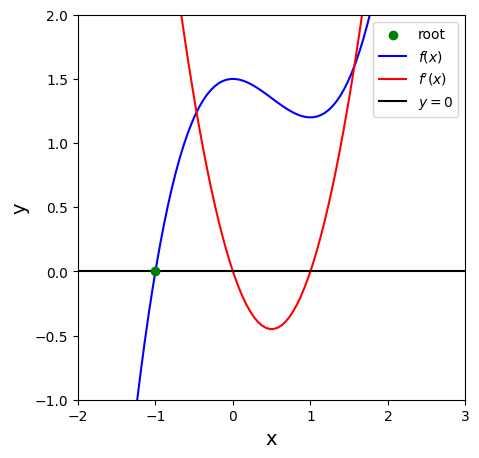

In [35]:
# import libraries
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return 1.5 - 0.9*x**2 + 0.6*x**3

def fp(x):
    return -1.8*x + 1.8*x**2

x = np.linspace(-2, 3, 100)
def plot_func(f):
    fig, ax = plt.subplots(1,1, figsize=(5,5))
    ax.set_ylim(-1,2)
    ax.set_xlim(-2,3)
    ax.set_xlabel("x",fontsize=14)
    ax.set_ylabel("y",fontsize=14)
    ax.scatter([-1], [0], color="green", zorder=10, label="root")
    ax.plot(x, f(x), color="blue", label="$f(x)$")
    ax.plot(x, fp(x), color="red", label="$f'(x)$")
    ax.axhline(0, color="k", label="$y=0$")
    ax.legend()
    return fig, ax
plot_func(f=f)

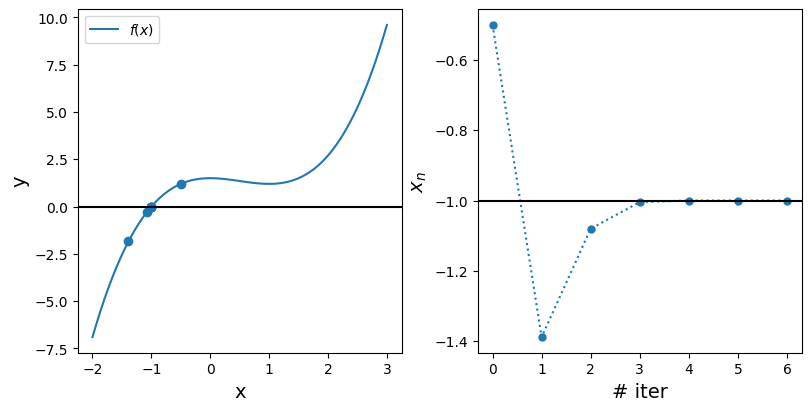

In [38]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib import animation
from IPython.display import HTML,clear_output

#iterative map
def newton(f, Nmax, x0, eps=1e-10):
    s = x0
    x = []
    y = []
    for i in range(Nmax+1):
        x.append(s)
        y.append(f(s))
        if np.allclose(y[-1], 0, atol=eps, rtol=0):
            break
        s -= f(s)/fp(s)
    return np.array(x), np.array(y)

def make_plot(f, x0, Nmax=200):
    x = np.linspace(-2, 3,100)
    xn, yn = newton(f=f, x0=x0, Nmax=Nmax)
    xn_iter_index = list(range(len(xn)))

    fig, axs = plt.subplots(1, 2, figsize=(8,4), constrained_layout=True)
    # left panel
    axs[0].plot(x, f(x), label="$f(x)$")
    axs[0].axhline(0, c="k")
    axs[0].scatter(xn, yn, marker="o")
    axs[0].set_xlabel("x", fontsize = 14)
    axs[0].set_ylabel("y", fontsize = 14)
    axs[0].legend()

    # right panel
    axs[1].plot(xn_iter_index, xn, ls=":", marker="o", ms=5)
    axs[1].set_ylabel("$x_n$", fontsize = 14)
    axs[1].set_xlabel("# iter", fontsize = 14)
    axs[1].axhline(xn[-1], c="k")
    return fig, axs, pd.DataFrame({"xn": xn, "yn": yn})
fig, axs, df = make_plot(f=f, x0=-0.5, Nmax=200)


In [69]:
df

,xn,yn
0,-0.500000,1.200000e+00
1,-1.388889,-1.843621e+00
2,-1.080189,-3.063535e-01
3,-1.004446,-1.605764e-02
4,-1.000015,-5.311280e-05
5,-1.000000,-5.876795e-10
6,-1.000000,0.000000e+00


**Newton's method doesn't always converge.** In the previous example, when do you expect Newton's method to fail?

Below is the example $f(x) = \tan^{-1}(x)$, where there is a root at $x=0$. The slope of the functions becomes very small for $x$-values with a large magnitude and hence the tangent lines approach a line parallel to the $x$-axis which intersects the $y$-axis at infinity.

**The (rate of) convergence may strongly depend on the initial guess $x_0$** as can be seen in the example(s) below:

/var/folders/7q/6d2x7jlj5rq4ktznvq0xp2xw0000gr/T/ipykernel_71520/1169880080.py:8: RuntimeWarning: overflow encountered in scalar power
  return 1/(1+x**2)
/var/folders/7q/6d2x7jlj5rq4ktznvq0xp2xw0000gr/T/ipykernel_71520/2800831708.py:17: RuntimeWarning: divide by zero encountered in scalar divide
  s -= f(s)/fp(s)
/var/folders/7q/6d2x7jlj5rq4ktznvq0xp2xw0000gr/T/ipykernel_71520/2800831708.py:17: RuntimeWarning: invalid value encountered in scalar subtract
  s -= f(s)/fp(s)


,xn,yn
0,1.500000,0.982794
1,-1.694080,-1.037546
2,2.321127,1.164002
3,-5.114088,-1.377695
4,32.295684,1.539842
...,...,...
196,NaN,NaN
197,NaN,NaN
198,NaN,NaN
199,NaN,NaN


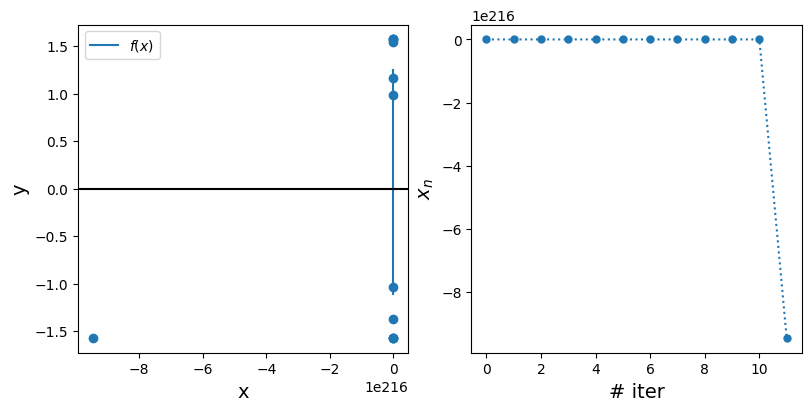

In [46]:
import numpy as np
from matplotlib import pyplot as plt

def f(x):
    return np.arctan(x)

def fp(x):
    return 1/(1+x**2)

fig, axs, df = make_plot(f=f, x0=1.5, Nmax=200)  # we expect here an error!
df 

What happens if we change the initial value?

,xn,yn
0,5.000000e-01,4.636476e-01
1,-7.955951e-02,-7.939228e-02
2,3.353022e-04,3.353022e-04
3,-2.513147e-11,-2.513147e-11


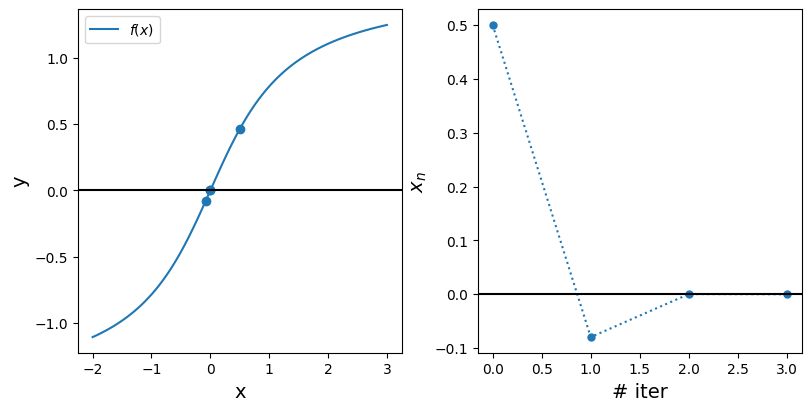

In [85]:
fig, axs, df = make_plot(f=f, x0=0.5, Nmax=200)
df

### Convergence and Truncation Error

To make this method useful, we need to estimate an error in the value of the root $x^*$ at which we can stop the procedure. We define the errors of the $n$-th and $(n+1)$-th estimate of the root as 

\begin{align}
\epsilon_n &= x^* -x_n\\
\epsilon_{n+1} &= x^* - x_{n+1}
\end{align}

Let's perform a Taylor series expansion (up to second order) of $f(x^*)$ about our (current) estimate $x_n$ of the root:

$$
f(x^*) \equiv 0 = f(x_n) + (x^*-x_n)f'(x_n) + \frac{1}{2} (x^*-x_n)^2 f''(x_n)
$$

We can devide this equation by $f'(x_n) \neq 0$ and rearrange the terms to obtain

$$
x^* = \underbrace{\left ( x_n - \frac{f(x_n)}{f'(x_n)}\right )}_{=x_{n+1}} - \frac{1}{2} \underbrace{(x^*-x_n)^2}_{=\epsilon_n^2} \frac{f''(x_n)}{f'(x_n)}
$$

Hence, rearrange once more, we find:
 
$$
\boxed{\epsilon_{n+1} = - {1 \over 2}\epsilon_n^2 {f^{\prime\prime}(x_n) \over f^\prime(x_n)}}
$$

The error decreases (roughly) with the square of the previous, i.e. with **quadratic convergence**. This **very fast convergence** is an advantage of this method over the previous methods we discussed. 


To obtain the actual value of the error, we reconsider the above

\begin{align}
\epsilon_n &= x^* -x_n\\
\epsilon_{n+1} &= x^* - x_{n+1}
\end{align}

Because $ \epsilon_{n+1} \propto \epsilon_{n}^2 \ll \epsilon_{n}$ we can write 

$$
\left | x_n - x_{n+1} \right | = \left | \epsilon_{n} - \epsilon_{n+1} \right | \approx \left | \epsilon_{n} \right |
$$

i.e. we can neglect $\epsilon_{n+1}$ versus $\epsilon_n$. This implies that we can also neglect $\epsilon_{n+1}$ in the second equation above, i.e. $x_{n+1}\approx x^*$, and hence for the error

$$
|\epsilon_n| = \left | x_n - x^* \right | \approx \left | x_n - x_{n+1} \right |
$$  

Hence, the convergence is so fast that we can **assume the error in the last iteration is negligible compared to the one in the previous iteration** and thus know our total error is less than the difference between the two.

In summary

$$
\boxed{\left | \epsilon_{n} \right | \approx \left | x_n - x_{n+1}\right |}
$$

Let's compare the estimated error with the actual error:

In [53]:
import numpy as np

def f(x):
    return 1.5 - 0.9*x**2 + 0.6*x**3

def fp(x):
    return -1.8*x +1.8*x**2

x1 = - 0.5
error_estimate = 1
num_iter = 0
num_iter_max = 100
while error_estimate > 1e-5:
    x2 = x1 - f(x1)/fp(x1)
    error_estimate = abs(x2-x1)
    error_actual = abs(-1-x1)
    print(f"x = {x1:1.8e},  error estimate =  {error_estimate:1.8e}, actual error= {error_actual:1.8e}, conservative? {error_actual < error_estimate}")
    x1=x2
    num_iter+=1
    if num_iter > num_iter_max:
        break        

x = -5.00000000e-01,  error estimate =  8.88888889e-01, actual error= 5.00000000e-01, conservative? True
x = -1.38888889e+00,  error estimate =  3.08699397e-01, actual error= 3.88888889e-01, conservative? False
x = -1.08018949e+00,  error estimate =  7.57438747e-02, actual error= 8.01894918e-02, conservative? False
x = -1.00444562e+00,  error estimate =  4.43086373e-03, actual error= 4.44561712e-03, conservative? False
x = -1.00001475e+00,  error estimate =  1.47532298e-05, actual error= 1.47533930e-05, conservative? False
x = -1.00000000e+00,  error estimate =  1.63244307e-10, actual error= 1.63244307e-10, conservative? False


**However, Newton’s method has two main issues: 1) we need to be able to calculate derivatives, and 2) it doesn’t always converge.**

If $f'(x)$ is very small, the error can get larger with each iteration, and if the function slopes the wrong way, we can get farther away instead of closer to the root.

[Link to upper error bounds](https://math.libretexts.org/Bookshelves/Calculus/CLP-1_Differential_Calculus_(Feldman_Rechnitzer_and_Yeager)/06%3A_Appendix/6.03%3A_C-_Root_Finding/6.3.02%3A_C.2_The_Error_Behaviour_of_Newton%27s_Method)

### Library functions
The `scipy.optimize` package has a function for Newton's method for a single variable, for more info click [`scipy.optimize.newton()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.newton.html):

```python3
scipy.optimize.newton(func, x0, fprime=None, args=(), tol=1.48e-08, maxiter=50, fprime2=None, x1=None, rtol=0.0, full_output=False, disp=True)
```

## Newton's method for equations with several variables

We now investigate the problem where we have 
* **$n$ coupled nonlinear equations**
* **for the $n$ variables** $x_1,x_2,\ldots,x_n$, i.e.

$$
f_i(x_1,x_2,\ldots,x_n) \equiv f_i(\vec{x})= 0 ~~~,~~~i=1,2,\ldots,n
$$

We assume there is a solution 

$$
\vec{x}^* = \left ( x_1^*,x_2^*,\ldots,x_n^* \right )
$$

As before, we define a **starting point**

$$
\vec{x}^{(1)} = \left ( x_1^{(1)},x_2^{(1)},\ldots,x_n^{(1)}\right )
$$

We expand each function $f_i(\vec{x})$ about $\vec{x}^{(1)}$, i.e.

$$
f_i(\vec{x}) = f_i(\vec{x}^{(1)}) + \nabla f_i(\vec{x}^{(1)})\cdot \left ( \vec{x} - \vec{x}^{(1)} \right )
+ \ldots ~~~,~~~ i =1,2,\ldots,n
$$

and then project to the values of $\vec{x}^{(2)}$ at which all functions vanish, i.e.

$$
f_i(\vec{x}^{(1)}) + \nabla f_i(\vec{x}^{(1)})\cdot 
\underbrace{\left ( \vec{x}^{(2)} - \vec{x}^{(1)} \right )}_{=\vec{\Delta x}} \overset{!}{=} 0
$$

with the Jacobian $\nabla f_i(\vec{x}^{(1)})$. In the explicit form, we have:

$$
\begin{pmatrix}
 f_1(\vec{x}_1) \\ f_2(\vec{x}_1) \\ \vdots \\ f_n(\vec{x}_1)
 \end{pmatrix}
+ 
\underbrace{\begin{pmatrix}
  {\partial f_1 \over \partial x_1} & {\partial f_1 \over \partial x_2} & \cdots & {\partial f_1 \over \partial x_n} \\
  {\partial f_2\ \over \partial x_1} & {\partial f_2 \over \partial x_2} & \cdots & {\partial f_2\over \partial x_n} \\
  \vdots  & \vdots  & \ddots & \vdots  \\
  {\partial f_n\over \partial x_1} & {\partial f_n\over \partial x_2} & \cdots & {\partial f_n\over \partial x_n}
\end{pmatrix}}_{=\bf{A}}
\cdot
\begin{pmatrix}
 \Delta x_1  \\ \Delta x_2 \\ \vdots \\ \Delta x_n
\end{pmatrix}
 = 
\begin{pmatrix} 
 0 \\ 0 \\ \vdots \\ 0
\end{pmatrix}
$$

This constitutes a **set of coupled linear equations** that can be solved with the standard models resulting in the vector
$\vec{\Delta x}$ and the estimate for the root

$$
\boxed{
\vec{x}^{(2)} = \vec{x}^{(1)} + \vec{\Delta x}}
$$

This procedure can repeated until the required accuracy of the root is achieved. **However, we have to calculate the Jacobian matrix at each step, which can be computationally expensive.**  

The **truncation error** is just like the above because of the quadratic convergence

$$
\boxed{
\epsilon_n = \left | \vec{x}_{n+1} - \vec{x}_{n} \right |}
$$

### Example
We consider the **set of two nonlinear equations**

\begin{align}
f_1(x,y) &= x^2 + y^2 -1 \\
f_2(x,y) &= y - x
\end{align}

We are looking for the roots, i.e., the values $(x^*,y^*)$ for which

\begin{align}
f_1(x^*,y^*) &= 0 \\
f_2(x^*,y^*) &= 0
\end{align}

Obtaining the **exact solutions** is straightforward in this particular case:

$$
x^* = y^* = \pm {1 \over \sqrt{2}} \approx \pm 0.707106781
$$

Let's visualize the problem:

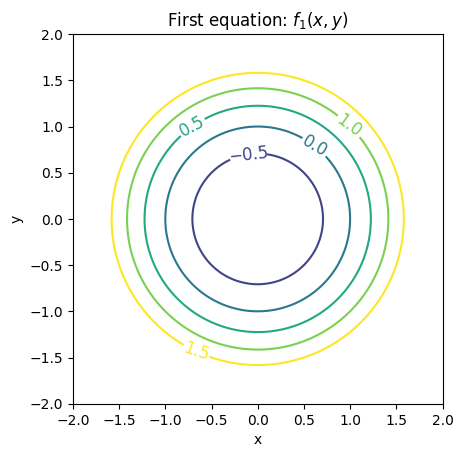

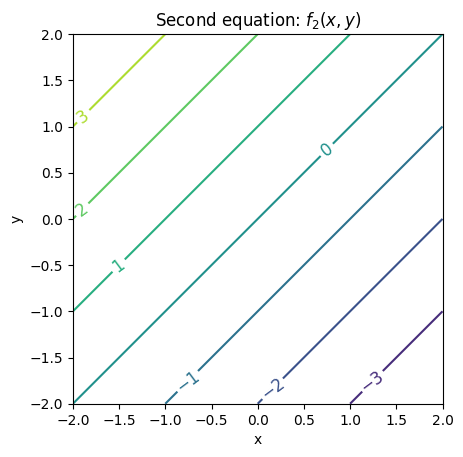

In [56]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-2,2,100)
y = np.linspace(-2,2,100)
u,v = np.meshgrid(x,y)

f1 = u**2 + v**2 - 1
plt.ylabel("y")
plt.xlabel("x")
plt.title("First equation: $f_1(x,y)$")
contour_levels = np.arange(-1, 2, 0.5)
cs1 = plt.contour(f1, extent=(-2,2,-2,2), levels=contour_levels)
plt.clabel(cs1, fontsize = 12)
plt.gca().set_aspect('equal')
plt.show()

f2 = v - u
cs2 = plt.contour(f2,extent=(-2,2,-2,2))
plt.clabel(cs2,fontsize = 12)
plt.ylabel("y")
plt.xlabel("x")
plt.title("Second equation: $f_2(x,y)$")
plt.gca().set_aspect('equal')
plt.show()

Let's recall `numpy`'s function `meshgrid`:

In [64]:
nx, ny = (5, 3)
x = np.linspace(0, 1, nx)
y = np.linspace(0, 1, ny)
xv, yv = np.meshgrid(x, y)
xv

array([[0.  , 0.25, 0.5 , 0.75, 1.  ],
       [0.  , 0.25, 0.5 , 0.75, 1.  ],
       [0.  , 0.25, 0.5 , 0.75, 1.  ]])

In [65]:
yv

array([[0. , 0. , 0. , 0. , 0. ],
       [0.5, 0.5, 0.5, 0.5, 0.5],
       [1. , 1. , 1. , 1. , 1. ]])

#### Solution
The Jacobian matrix is obtained as

$$
\begin{pmatrix}
  {\partial f_1 \over \partial x} & {\partial f_1 \over \partial y} \\
  {\partial f_2 \over \partial x}& {\partial f_2 \over \partial y}
 \end{pmatrix}
 =
 \begin{pmatrix}
  2x & 2y \\
  -1 & 1
 \end{pmatrix}
$$

and hence

$$
\begin{pmatrix}
  2x_n & 2y_n \\
  -1 & 1
\end{pmatrix}
\cdot 
\begin{pmatrix} 
x_{n+1}-x_n \\ y_{n+1}-y_n
\end{pmatrix}
= 
-
\begin{pmatrix} 
f_1(x_n,y_n)\\f_2(x_n,y_n)
\end{pmatrix}
$$

In [70]:
# solution of x**2 + y**2 = R**2 and y = x

import numpy as np
from numpy.linalg import solve

def f1(x,y):
    return x**2 + y**2 - 1
    
def f2(x,y):
    return y - x

# exact solutions
x_e = 1/np.sqrt(2)
y_e = 1/np.sqrt(2)

# starting point
x1=-2
y1=-1
for i in range(0, 20, 1):
    
    # set the vector
    v = -np.array([f1(x1,y1),
                   f2(x1,y1)])

    # set the Jacobian matrix
    A = np.array([[2*x1, 2*y1],
                  [-1, 1]])

    # solve the linear system
    delta = solve(A,v)

    # obtain updated estimate for the root
    x2 = x1 + delta[0]
    y2 = y1 + delta[1]    
    print(f"x = {x2:1.10e}, y = {y2:1.10e}")

    # update current point
    x1=x2
    y1=y2

print("\nComparison with exact solution:")
print("x = %1.10e, x_exact = (+/-) %1.10e"%(x2, x_e))
print("y = %1.10e, y_exact = (+/-) %1.10e"%(y2, y_e))

x = -1.0000000000e+00, y = -1.0000000000e+00
x = -7.5000000000e-01, y = -7.5000000000e-01
x = -7.0833333333e-01, y = -7.0833333333e-01
x = -7.0710784314e-01, y = -7.0710784314e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01
x = -7.0710678119e-01, y = -7.0710678119e-01

Comparison with exact solution:
x = -7.0710678119e-01, x_exact = (+/-) 7.0710678119e-01
y = -7.0710

### Visualization of the approach

initial configuration


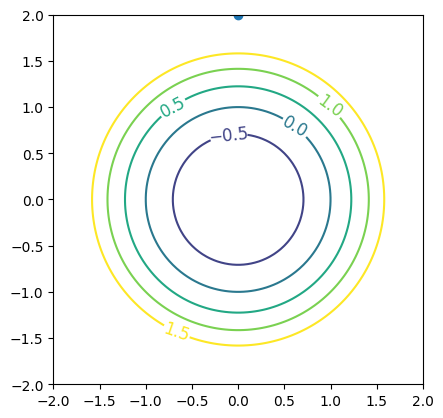

x = 0.0000000000e+00, y = 2.0000000000e+00
--------------------------------------------------


x = 1.2500000000e+00, y = 1.2500000000e+00


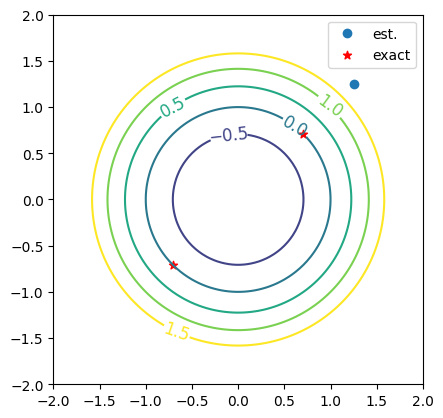

x = 8.2500000000e-01, y = 8.2500000000e-01


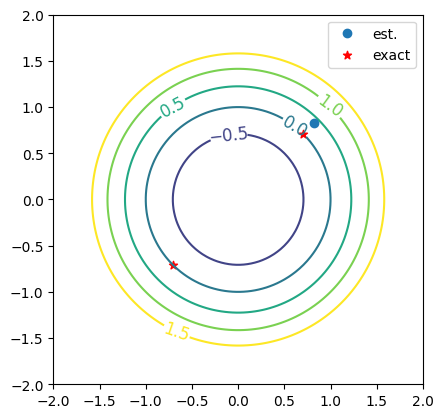

x = 7.1553030303e-01, y = 7.1553030303e-01


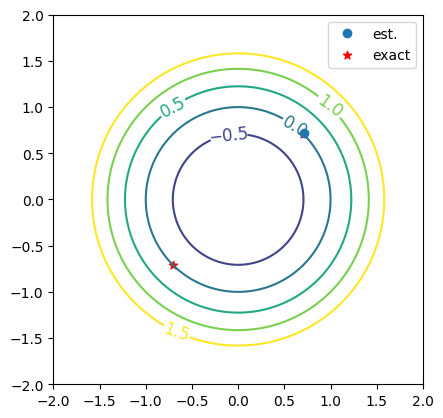

x = 7.0715636380e-01, y = 7.0715636380e-01


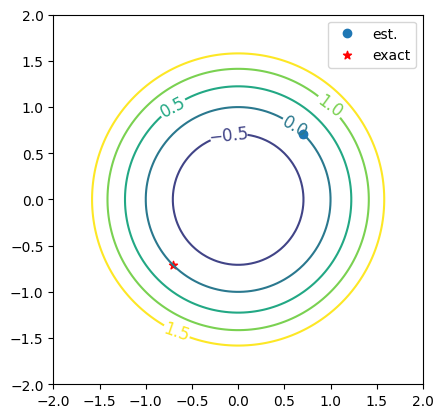

x = 7.0710678292e-01, y = 7.0710678292e-01


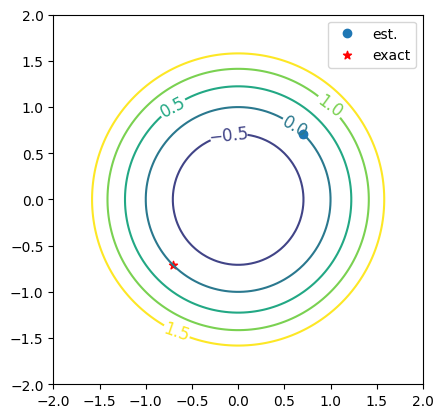


Comparison with exact solution:
x = 7.0710678292e-01, x_exact = (+/-) 7.0710678119e-01
y = 7.0710678292e-01, y_exact = (+/-) 7.0710678119e-01


In [92]:
# solution of x**2 + y**2 = R**2 and y = x

import numpy as np
from numpy.linalg import solve

def f1(x,y):
    return x**2 + y**2 - 1
    
def f2(x,y):
    return y - x

# exact solutions
x_e = 1/np.sqrt(2)
y_e = 1/np.sqrt(2)

x = np.linspace(-2,2,100)
y = np.linspace(-2,2,100)
u,v = np.meshgrid(x,y)
fplot = u**2 + v**2 - 1
contour_levels = np.arange(-1,2,0.5)


# starting point
x1=0; y1=2
print("initial configuration")
cs1 = plt.contour(fplot, extent=(-2,2,-2,2), levels=contour_levels)
plt.clabel(cs1, fontsize=12)
plt.plot([x1], [y1], "o")
plt.gca().set_aspect('equal')
plt.show()
print(f"x = {x1:1.10e}, y = {y1:1.10e}")
print(50*"-" + 2*"\n")

for i in range(0,5,1):
    # set the vector
    v = -np.array([f1(x1,y1),f2(x1,y1)])

    # set the Jacobian matrix
    A = np.array([[2*x1,2*y1],[-1,1]])

    # solve for difference vector
    delta = solve(A,v)

    # obtain new estimate for the root
    x2 = x1 + delta[0]
    y2 = y1 + delta[1]    
    print(f"x = {x2:1.10e}, y = {y2:1.10e}")

    # update 
    x1=x2
    y1=y2
    
    cs1 = plt.contour(fplot, extent=(-2,2,-2,2), levels=contour_levels)
    plt.clabel(cs1, fontsize = 12)
    plt.plot([x1], [y1], "o", label="est.")
    loc = np.array([+1,-1])/np.sqrt(2)
    plt.scatter(loc, loc, color="red", marker="*", label="exact")
    plt.gca().set_aspect('equal')
    plt.legend()
    plt.show()

print("\nComparison with exact solution:")
print("x = %1.10e, x_exact = (+/-) %1.10e"%(x2, x_e))
print("y = %1.10e, y_exact = (+/-) %1.10e"%(y2, y_e))

### Error Estimates

In [80]:
# solution of x**2 + y**2 = R**2 and y = x
import numpy as np
from numpy.linalg import solve

def f1(x,y):
    return x**2 + y**2 - 1
    
def f2(x,y):
    return y - x

# exact solutions
x_e = 1/np.sqrt(2)
y_e = 1/np.sqrt(2)

# starting point
x1=1.5
y1=0.8
error_est = 1

while error_est > 1.0e-10:
    # set the vector
    v = -np.array([f1(x1,y1),f2(x1,y1)])

    # set the Jacobian matrix
    A = np.array([[2*x1,2*y1],[-1,1]])

    delta = solve(A,v)

    x2 = x1 + delta[0]
    y2 = y1 + delta[1]
    error_act = np.sqrt((x1 - x_e)**2 + (y1 - y_e)**2)
    error_est = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    
    print(f"x = {x2:1.10e}, y = {y2:1.10e}")
    print(f"actual error = {error_act:1.5e}, estimated error = {error_est:1.5e}\n")
    x1=x2
    y1=y2

print("\nComparison with exact solution:")
print("x = %1.10e, x_exact = (+/-) %1.10e"%(x2, x_e))
print("y = %1.10e, y_exact = (+/-) %1.10e"%(y2, y_e))

x = 8.4565217391e-01, y = 8.4565217391e-01
actual error = 7.98316e-01, estimated error = 6.55938e-01

x = 7.1845590701e-01, y = 7.1845590701e-01
actual error = 1.95933e-01, estimated error = 1.79883e-01

x = 7.0719641971e-01, y = 7.0719641971e-01
actual error = 1.60501e-02, estimated error = 1.59233e-02

x = 7.0710678687e-01, y = 7.0710678687e-01
actual error = 1.26768e-04, estimated error = 1.26760e-04

x = 7.0710678119e-01, y = 7.0710678119e-01
actual error = 8.03405e-09, estimated error = 8.03405e-09

x = 7.0710678119e-01, y = 7.0710678119e-01
actual error = 1.57009e-16, estimated error = 1.57009e-16


Comparison with exact solution:
x = 7.0710678119e-01, x_exact = (+/-) 7.0710678119e-01
y = 7.0710678119e-01, y_exact = (+/-) 7.0710678119e-01


## The secant method

One of the problems with Newton’s method is that we have to be able to calculate the derivative. If we have an analytic expression for the function, then we can (more or less) straightforwardly compute derivatives, but if the values come from an experiment or a numerical calculation, we will not have an analytic expression in hand.

In these cases, we can always **approximate the derivative in Newton's method** by a finite difference as before; for instance,

$$
f'(x) \approx \frac{f(x+h) - f(x)}{h}
$$

However, we can be even more computationally efficient by using the **secant method**, closely related to Newton's method (i.e., **quasi-Newton method**). Here, instead of approximating the tangent line at one point, we construct the secant connecting two points $f(x_0)$ and $f(x_1)$. The procedure is illustrated for the first two iterations in this figure: 

<img src="./notes/Secant_method.svg" width="350">

Given two initial values $x_0$ and $x_1$, we can **construct the secant** (i.e., a line) through the two points $(x_0, f(x_0))$ and $(x_1, f(x_1))$:

$$\boxed{
S(x) = f(x_1) + \underbrace{\frac{f(x_1) - f(x_0)}{x_1 - x_0}}_{=\text{slope}}(x - x_1) \,.}
$$

We can straightforwardly verify that the secant indeed goes through the two points:

\begin{align}
S(x_0) &= f(x_0) \\
S(x_1) &= f(x_1)
\end{align}

Next, we determine the next point $x_2$ of the iteration such that $S(x_2) = 0$ as the **root of $S(x)$**, leading to
$$\boxed{
x_2 = x_1 - f(x_1) \frac{x_1 - x_0}{f(x_1) - f(x_0)} } \,.
$$

We **continue this process** with points $x_2$ (instead of $x_1$) and $x_1$ (instead of $x_0$) to obtain the next point, $x_3$:

\begin{equation}
x_3 = x_2 - f(x_2) \frac{x_2 - x_1}{f(x_2) - f(x_1)}, 
\end{equation}

In general, given the two initial values $x_0$ and $x_1$, one has the **recurrence relation** for the secant method:

$$\boxed{
x_n = x_{n-1} - f(x_{n-1}) \frac{x_{n-1} - x_{n-2}}{f(x_{n-1}) - f(x_{n-2})} }\,.
$$

Note that the secant method **approximates the derivative using the previous approximation**.

One iterates until the requested tolerance for the error

$$
\boxed{\left | \epsilon_{n} \right | \approx \left | x_n - x_{n+1}\right |}
$$

is achieved. The secant method achieves a slightly slower convergence rate than Newton's method, so-called **sub-quadratic convergence**.

In [1]:
import numpy as np

def f(x):
    return 1.5 - 0.9*x**2 + 0.6*x**3

x0 = -0.5
x1 = -1.5
# h = 1e-4; x1 = x0 + h
error_estimate = 1
req_eps = 1e-9

for i in range(1,150+1) :
    slope = (f(x1) - f(x0)) / (x1 - x0)
    x2 = x1 - f(x1) / slope
    error_estimate = abs(x2 - x1)
    error_actual = abs(-1 - x1)
    print(f"iter #{i} \t est. root: {x2:e}\tactual error: {error_actual:e}\test. error: {error_estimate:e}")
    x0 = x1
    x1 = x2
    if error_estimate < req_eps:
        break

iter #1 	 est. root: -8.200000e-01	actual error: 5.000000e-01	est. error: 6.800000e-01
iter #2 	 est. root: -9.431634e-01	actual error: 1.800000e-01	est. error: 1.231634e-01
iter #3 	 est. root: -1.008758e+00	actual error: 5.683664e-02	est. error: 6.559445e-02
iter #4 	 est. root: -9.996170e-01	actual error: 8.757803e-03	est. error: 9.140768e-03
iter #5 	 est. root: -9.999975e-01	actual error: 3.829645e-04	est. error: 3.804601e-04
iter #6 	 est. root: -1.000000e+00	actual error: 2.504366e-06	est. error: 2.505086e-06
iter #7 	 est. root: -1.000000e+00	actual error: 7.194589e-10	est. error: 7.194603e-10


## Other library implementations

[`scipy.optimize()`](https://docs.scipy.org/doc/scipy/reference/optimize.html) implements various algorithms:
* [scalar functions](https://docs.scipy.org/doc/scipy/reference/optimize.html#scalar-functions), including Brent’s method (combining the bisection method, secant method, and inverse quadratic interpolation).
* [multi-dimensional functions](https://docs.scipy.org/doc/scipy/reference/optimize.html#multidimensional), including Broyden's method.

Interesting applications of the **modified Broyden's method** (i.e., a quasi-Newton method) in the context of (nuclear) physics have been studied by Baran, Bulgac, Forbes, Hagen, Nazarewicz, Schunck, and Stoitsov in [Phys. Rev. C **78**, 014318](https://journals.aps.org/prc/abstract/10.1103/PhysRevC.78.014318).

See Section II.B in that paper. It's a **multi-variate method**. Here's the abstract of the paper:

> **Abstract:**
> Broyden's method, **widely used in quantum chemistry** electronic-structure calculations for the numerical solution of nonlinear equations in many variables, is applied in the context of the nuclear many-body problem. **Examples include** the unitary gas problem, the **nuclear density functional theory** with Skyrme functionals, and the **nuclear coupled-cluster theory**. The stability of the method, its ease of use, and its rapid convergence rates make **Broyden's method a tool of choice for large-scale nuclear structure calculations**.